In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image, ImageFile
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [2]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Paths
DATA_DIR = Path("../raw/airbus-ship-detection/train_v2")
TRAIN_CSV = Path("../splits/train.csv")
VAL_CSV = Path("../splits/validation.csv")
TEST_CSV = Path("../splits/test.csv")
CHECKPOINT_PATH = Path("../checkpoints/simclr_best.pt")

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Verify files
for path in [DATA_DIR, TRAIN_CSV, VAL_CSV, TEST_CSV, CHECKPOINT_PATH]:
    print(f"{path}: {'Found' if path.exists() else 'MISSING'}")

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
../raw/airbus-ship-detection/train_v2: Found
../splits/train.csv: Found
../splits/validation.csv: Found
../splits/test.csv: Found
../checkpoints/simclr_best.pt: Found


In [ ]:
checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=DEVICE, weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"{key}: Tensor {tuple(value.shape)}")
        else:
            print(f"{key}: {type(value).__name__}")

Checkpoint type: <class 'dict'>

Checkpoint keys:
epoch: int
model_state_dict: dictionary with 124 entries
optimizer_state_dict: dictionary with 2 entries
scaler_state_dict: dictionary with 5 entries
config: dictionary with 9 entries
history: list
step_history: list
step_tracker: dictionary with 3 entries
validation_metrics: dictionary with 5 entries


In [4]:
state_dict = checkpoint["model_state_dict"]

print("Total parameters:", len(state_dict))

print("\nFirst 30 parameter names:")
for key in list(state_dict.keys())[:30]:
    print(key, state_dict[key].shape)

print("\nLast 15 parameter names:")
for key in list(state_dict.keys())[-15:]:
    print(key, state_dict[key].shape)

Total parameters: 124

First 30 parameter names:
encoder.conv1.weight torch.Size([64, 3, 7, 7])
encoder.bn1.weight torch.Size([64])
encoder.bn1.bias torch.Size([64])
encoder.bn1.running_mean torch.Size([64])
encoder.bn1.running_var torch.Size([64])
encoder.bn1.num_batches_tracked torch.Size([])
encoder.layer1.0.conv1.weight torch.Size([64, 64, 3, 3])
encoder.layer1.0.bn1.weight torch.Size([64])
encoder.layer1.0.bn1.bias torch.Size([64])
encoder.layer1.0.bn1.running_mean torch.Size([64])
encoder.layer1.0.bn1.running_var torch.Size([64])
encoder.layer1.0.bn1.num_batches_tracked torch.Size([])
encoder.layer1.0.conv2.weight torch.Size([64, 64, 3, 3])
encoder.layer1.0.bn2.weight torch.Size([64])
encoder.layer1.0.bn2.bias torch.Size([64])
encoder.layer1.0.bn2.running_mean torch.Size([64])
encoder.layer1.0.bn2.running_var torch.Size([64])
encoder.layer1.0.bn2.num_batches_tracked torch.Size([])
encoder.layer1.1.conv1.weight torch.Size([64, 64, 3, 3])
encoder.layer1.1.bn1.weight torch.Size([64]

In [4]:
from torchvision.models import resnet18


class SimCLRClassifier(nn.Module):
    def __init__(self, checkpoint_path):
        super().__init__()

        self.encoder = resnet18(weights=None)

        # Remove the original ImageNet classification layer
        self.encoder.fc = nn.Identity()

        # Load pretrained SimCLR encoder
        checkpoint = torch.load(
            checkpoint_path, map_location="cpu", weights_only=False
        )

        encoder_weights = {
            key.replace("encoder.", ""): value
            for key, value in checkpoint["model_state_dict"].items()
            if key.startswith("encoder.")
        }

        self.encoder.load_state_dict(encoder_weights)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2)
        )

    def forward(self, x):
        features = self.encoder(x)
        return self.classifier(features)


model = SimCLRClassifier(CHECKPOINT_PATH).to(DEVICE)

print(model)

SimCLRClassifier(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1

In [9]:
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nTraining sample:")
display(train_df.head())

print("\nTraining label distribution:")
print(train_df.iloc[:, -1].value_counts())

Training: (134789, 2)
Validation: (28883, 2)
Test: (28884, 2)

Columns:
['ImageId', 'has_ship']

Training sample:


,ImageId,has_ship
0,e5698ecf6.jpg,0
1,36ca35038.jpg,0
2,dbc649155.jpg,0
3,5c263d1ae.jpg,1
4,32039c518.jpg,0



Training label distribution:
has_ship
0    105000
1     29789
Name: count, dtype: int64


In [11]:
IMAGE_SIZE = 224

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.8, 1.0),
            ratio=(0.9, 1.1),
            interpolation=transforms.InterpolationMode.BICUBIC,
        ),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

eval_transform = transforms.Compose(
    [
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=transforms.InterpolationMode.BICUBIC,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

In [7]:
class ShipDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = self.image_dir / row["ImageId"]
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(row["has_ship"], dtype=torch.long)

        return image, label

In [12]:
BATCH_SIZE = 32
NUM_WORKERS = 4

train_dataset = ShipDataset(train_df, DATA_DIR, train_transform)
val_dataset = ShipDataset(val_df, DATA_DIR, eval_transform)
test_dataset = ShipDataset(test_df, DATA_DIR, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 4213
Validation batches: 903
Test batches: 903


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

class_weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=train_df["has_ship"].values
)

class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

print("Class weights:")
print("No Ship:", class_weights[0].item())
print("Ship:", class_weights[1].item())

Class weights:
No Ship: 0.6418523788452148
Ship: 2.2623956203460693


In [ ]:
EPOCHS = 10

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    [
        {"params": model.encoder.parameters(), "lr": 1e-5},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)

scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

print("Epochs:", EPOCHS)
print("Encoder LR:", optimizer.param_groups[0]["lr"])
print("Classifier LR:", optimizer.param_groups[1]["lr"])

Epochs: 10
Encoder LR: 1e-05
Classifier LR: 0.001


In [ ]:
from sklearn.metrics import average_precision_score
from tqdm.auto import tqdm


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()

    running_loss = 0.0

    progress = tqdm(loader, desc="Training")

    for images, labels in progress:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return running_loss / len(loader)

/home/abhi/Dev/varuna-ssl/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probabilities = []

    for images, labels in tqdm(loader, desc="Validation"):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        probabilities = torch.softmax(outputs.float(), dim=1)[:, 1]

        running_loss += loss.item()

        all_labels.extend(labels.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

    val_loss = running_loss / len(loader)

    pr_auc = average_precision_score(all_labels, all_probabilities)

    return val_loss, pr_auc

In [ ]:
CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "simclr_classifier_best.pt"

best_pr_auc = 0.0
history = []

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler
    )

    val_loss, val_pr_auc = validate(model, val_loader, criterion)

    scheduler.step(val_pr_auc)

    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_pr_auc": val_pr_auc,
        }
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation PR-AUC: {val_pr_auc:.4f}")

    if val_pr_auc > best_pr_auc:
        best_pr_auc = val_pr_auc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_pr_auc": best_pr_auc,
                "history": history,
            },
            BEST_MODEL_PATH,
        )

        print("Saved new best model!")

    print(
        f"Encoder LR: {optimizer.param_groups[0]['lr']:.2e} | "
        f"Classifier LR: {optimizer.param_groups[1]['lr']:.2e}"
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    CHECKPOINT_DIR / "simclr_classifier_history.csv", index=False
)

print("\nTraining completed.")
print("Best validation PR-AUC:", round(best_pr_auc, 4))


Epoch 1/10


Validation: 100%|██████████| 903/903 [01:09<00:00, 12.99it/s]


Train Loss: 0.3566
Validation Loss: 0.2662
Validation PR-AUC: 0.9032
Saved new best model!
Encoder LR: 1.00e-05 | Classifier LR: 1.00e-03

Epoch 2/10


Validation: 100%|██████████| 903/903 [01:06<00:00, 13.51it/s]


Train Loss: 0.2988
Validation Loss: 0.2388
Validation PR-AUC: 0.9161
Saved new best model!
Encoder LR: 1.00e-05 | Classifier LR: 1.00e-03

Epoch 3/10


Validation: 100%|██████████| 903/903 [01:08<00:00, 13.27it/s]


... (11 outputs left out)

Validation: 100%|██████████| 903/903 [01:06<00:00, 13.56it/s]


Train Loss: 0.2352
Validation Loss: 0.1804
Validation PR-AUC: 0.9464
Saved new best model!
Encoder LR: 1.00e-05 | Classifier LR: 1.00e-03

Epoch 10/10


Validation: 100%|██████████| 903/903 [01:08<00:00, 13.22it/s]

Train Loss: 0.2319
Validation Loss: 0.1821
Validation PR-AUC: 0.9462
Encoder LR: 1.00e-05 | Classifier LR: 1.00e-03

Training completed.
Best validation PR-AUC: 0.9464


In [ ]:
best_checkpoint = torch.load(
    BEST_MODEL_PATH, map_location=DEVICE, weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", best_checkpoint["epoch"])
print("Best validation PR-AUC:", best_checkpoint["best_val_pr_auc"])

Best epoch: 9
Best validation PR-AUC: 0.9463677659799417


In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast(
            device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs.float(), dim=1)[:, 1]
        predictions = (probabilities >= 0.5).long()

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

print("Test Accuracy:", accuracy_score(all_labels, all_predictions))
print("Test PR-AUC:", average_precision_score(all_labels, all_probabilities))

print("\nClassification Report:")
print(
    classification_report(
        all_labels, all_predictions, target_names=["No Ship", "Ship"], digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

Testing: 100%|██████████| 903/903 [01:07<00:00, 13.38it/s]

Test Accuracy: 0.9376817615288742
Test PR-AUC: 0.940913472430097

Classification Report:
              precision    recall  f1-score   support

     No Ship     0.9748    0.9444    0.9594     22500
        Ship     0.8235    0.9140    0.8664      6384

    accuracy                         0.9377     28884
   macro avg     0.8991    0.9292    0.9129     28884
weighted avg     0.9414    0.9377    0.9388     28884


Confusion Matrix:
[[21249  1251]
 [  549  5835]]


In [ ]:
test_results = pd.DataFrame(
    {
        "ImageId": test_df["ImageId"].values,
        "actual": all_labels,
        "predicted": all_predictions,
        "ship_probability": all_probabilities,
    }
)

test_results["correct"] = test_results["actual"] == test_results["predicted"]

print("Total test images:", len(test_results))
print("Correct predictions:", test_results["correct"].sum())
print("Incorrect predictions:", (~test_results["correct"]).sum())

display(test_results.head())

Total test images: 28884
Correct predictions: 27084
Incorrect predictions: 1800


,ImageId,actual,predicted,ship_probability,correct
0,e2802fef1.jpg,0,0,0.001315,True
1,c1ef9dd2f.jpg,0,0,0.007923,True
2,9fe4ddeef.jpg,0,0,0.122944,True
3,65964d1c5.jpg,0,0,0.000817,True
4,77a84331a.jpg,0,0,0.002884,True


In [18]:
ANNOTATION_CSV = Path(
    "../raw/airbus-ship-detection/train_ship_segmentations_v2.csv"
)

annotations = pd.read_csv(ANNOTATION_CSV)

print("Shape:", annotations.shape)
print("Columns:", annotations.columns.tolist())
display(annotations.head())

Shape: (231723, 2)
Columns: ['ImageId', 'EncodedPixels']


,ImageId,EncodedPixels
0,00003e153.jpg,NaN
1,0001124c7.jpg,NaN
2,000155de5.jpg,264661 17 265429 33 266197 33 266965 33 267733...
3,000194a2d.jpg,360486 1 361252 4 362019 5 362785 8 363552 10 ...
4,000194a2d.jpg,51834 9 52602 9 53370 9 54138 9 54906 9 55674 ...


In [19]:
def decode_rle(encoded_pixels, height=768, width=768):
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(encoded_pixels):
        return mask.reshape((height, width))

    values = np.asarray(encoded_pixels.split(), dtype=np.int64)

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    for start, end in zip(starts, ends):
        mask[start:end] = 1

    return mask.reshape((width, height)).T


def get_ship_coverage(group):
    combined_mask = np.zeros(768 * 768, dtype=np.uint8)

    for encoded_pixels in group["EncodedPixels"].dropna():
        values = np.asarray(encoded_pixels.split(), dtype=np.int64)

        starts = values[0::2] - 1
        lengths = values[1::2]

        for start, length in zip(starts, lengths):
            combined_mask[start : start + length] = 1

    return combined_mask.sum() / (768 * 768) * 100


coverage_df = (
    annotations.groupby("ImageId")
    .apply(get_ship_coverage)
    .reset_index(name="ship_coverage")
)

print("Images analyzed:", len(coverage_df))
display(coverage_df.head())

Images analyzed: 192556


,ImageId,ship_coverage
0,00003e153.jpg,0.000000
1,0001124c7.jpg,0.000000
2,000155de5.jpg,0.574409
3,000194a2d.jpg,0.247531
4,0001b1832.jpg,0.000000


In [20]:
test_results = test_results.merge(coverage_df, on="ImageId", how="left")

test_results["ship_coverage"] = test_results["ship_coverage"].fillna(0)

print("Total test images:", len(test_results))
print("Ship images:", (test_results["actual"] == 1).sum())
print("No-ship images:", (test_results["actual"] == 0).sum())

display(
    test_results[
        ["ImageId", "actual", "predicted", "ship_probability", "ship_coverage"]
    ].head()
)

Total test images: 28884
Ship images: 6384
No-ship images: 22500


,ImageId,actual,predicted,ship_probability,ship_coverage
0,e2802fef1.jpg,0,0,0.001315,0.0
1,c1ef9dd2f.jpg,0,0,0.007923,0.0
2,9fe4ddeef.jpg,0,0,0.122944,0.0
3,65964d1c5.jpg,0,0,0.000817,0.0
4,77a84331a.jpg,0,0,0.002884,0.0


In [21]:
coverage_bins = [0, 0.01, 0.05, 0.1, 0.5, 1, 2, 5, np.inf]

coverage_labels = [
    "<0.01%",
    "0.01-0.05%",
    "0.05-0.1%",
    "0.1-0.5%",
    "0.5-1%",
    "1-2%",
    "2-5%",
    ">5%",
]

ship_results = test_results[test_results["actual"] == 1].copy()

ship_results["coverage_group"] = pd.cut(
    ship_results["ship_coverage"],
    bins=coverage_bins,
    labels=coverage_labels,
    right=False,
)

coverage_analysis = (
    ship_results.groupby("coverage_group", observed=False)
    .agg(total=("actual", "count"), detected=("predicted", "sum"))
    .reset_index()
)

coverage_analysis["missed"] = (
    coverage_analysis["total"] - coverage_analysis["detected"]
)

coverage_analysis["recall"] = (
    coverage_analysis["detected"] / coverage_analysis["total"] * 100
)

display(coverage_analysis.round(2))

,coverage_group,total,detected,missed,recall
0,<0.01%,375,289,86,77.07
1,0.01-0.05%,1536,1298,238,84.51
2,0.05-0.1%,613,553,60,90.21
3,0.1-0.5%,1894,1783,111,94.14
4,0.5-1%,884,864,20,97.74
5,1-2%,748,721,27,96.39
6,2-5%,327,320,7,97.86
7,>5%,7,7,0,100.00


In [22]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "figure.dpi": 120,
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.fontsize": 10,
    }
)

print("Fine-tuned model visualization setup complete.")

Fine-tuned model visualization setup complete.


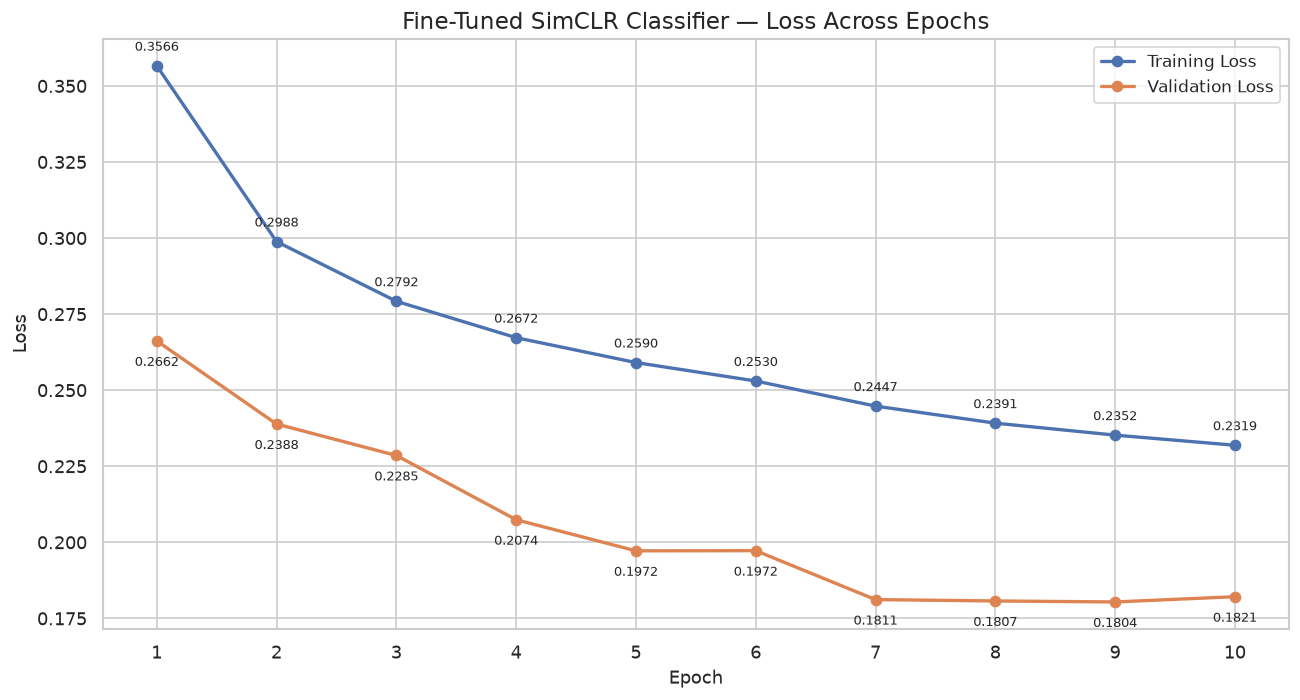

,epoch,train_loss,val_loss
0,1,0.3566,0.2662
1,2,0.2988,0.2388
2,3,0.2792,0.2285
3,4,0.2672,0.2074
4,5,0.2590,0.1972
5,6,0.2530,0.1972
6,7,0.2447,0.1811
7,8,0.2391,0.1807
8,9,0.2352,0.1804
9,10,0.2319,0.1821


In [39]:
history_df = pd.read_csv("../checkpoints/simclr_classifier_history.csv")

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    linewidth=2,
    label="Training Loss",
)

ax.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    linewidth=2,
    label="Validation Loss",
)

# Display values for both curves
for epoch, value in zip(history_df["epoch"], history_df["train_loss"]):
    ax.annotate(
        f"{value:.4f}",
        (epoch, value),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=8,
    )

for epoch, value in zip(history_df["epoch"], history_df["val_loss"]):
    ax.annotate(
        f"{value:.4f}",
        (epoch, value),
        textcoords="offset points",
        xytext=(0, -15),
        ha="center",
        fontsize=8,
    )

ax.set_title("Fine-Tuned SimCLR Classifier — Loss Across Epochs")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_xticks(history_df["epoch"])
ax.legend()

plt.tight_layout()
plt.show()

display(history_df[["epoch", "train_loss", "val_loss"]].round(4))

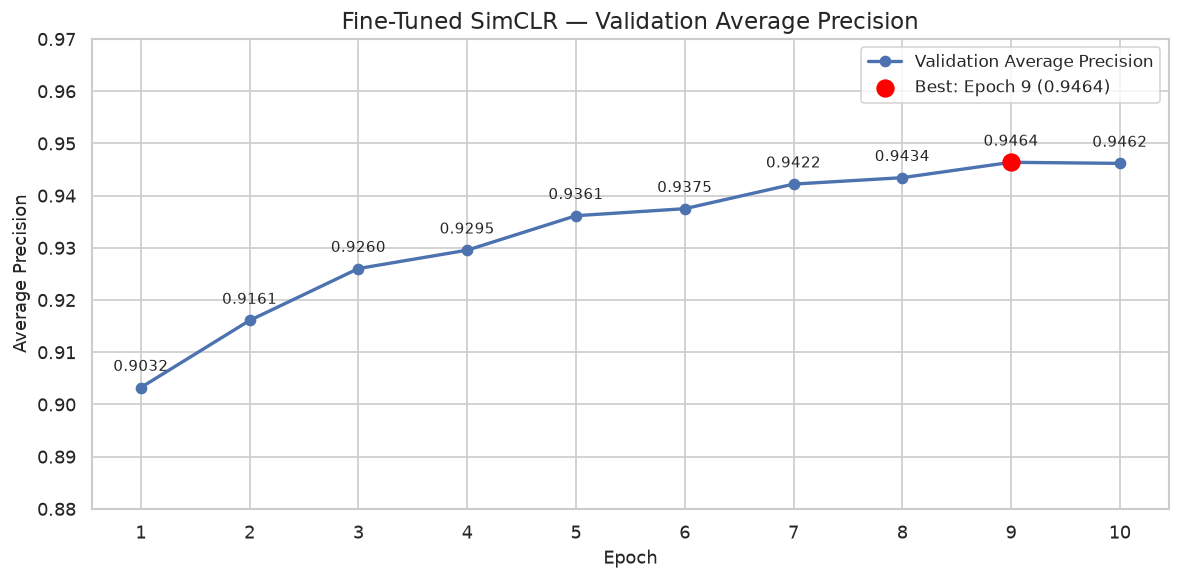

Best epoch: 9
Best validation AP: 0.9464


In [38]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    history_df["epoch"],
    history_df["val_pr_auc"],
    marker="o",
    linewidth=2,
    label="Validation Average Precision",
)

# Display values above every point
for epoch, value in zip(history_df["epoch"], history_df["val_pr_auc"]):
    ax.annotate(
        f"{value:.4f}",
        (epoch, value),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9,
    )

best_idx = history_df["val_pr_auc"].idxmax()
best_epoch = history_df.loc[best_idx, "epoch"]
best_ap = history_df.loc[best_idx, "val_pr_auc"]

ax.scatter(
    best_epoch,
    best_ap,
    color="red",
    s=100,
    zorder=5,
    label=f"Best: Epoch {best_epoch} ({best_ap:.4f})",
)

ax.set_title("Fine-Tuned SimCLR — Validation Average Precision")
ax.set_xlabel("Epoch")
ax.set_ylabel("Average Precision")
ax.set_xticks(history_df["epoch"])
ax.set_ylim(0.88, 0.97)
ax.legend()

plt.tight_layout()
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Best validation AP: {best_ap:.4f}")

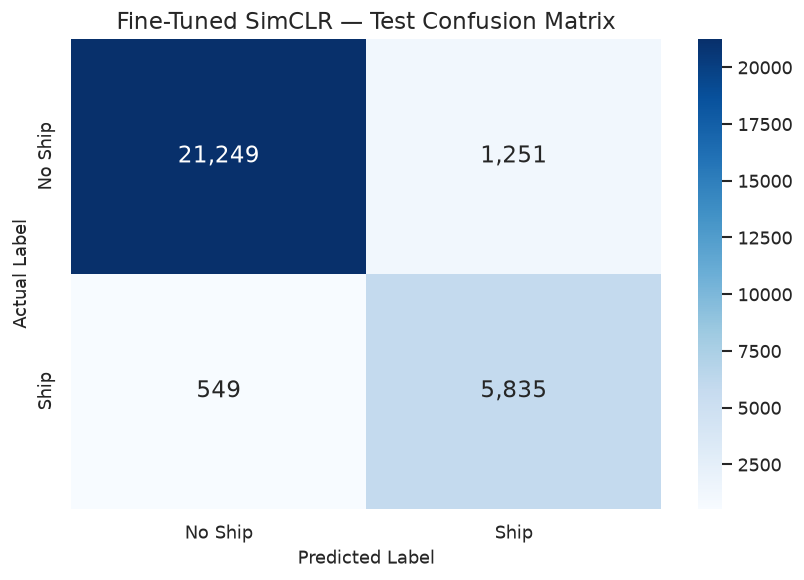

True Negatives : 21,249
False Positives: 1,251
False Negatives: 549
True Positives : 5,835


In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["No Ship", "Ship"],
    yticklabels=["No Ship", "Ship"],
    annot_kws={"size": 14},
)

plt.title("Fine-Tuned SimCLR — Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"True Negatives : {tn:,}")
print(f"False Positives: {fp:,}")
print(f"False Negatives: {fn:,}")
print(f"True Positives : {tp:,}")

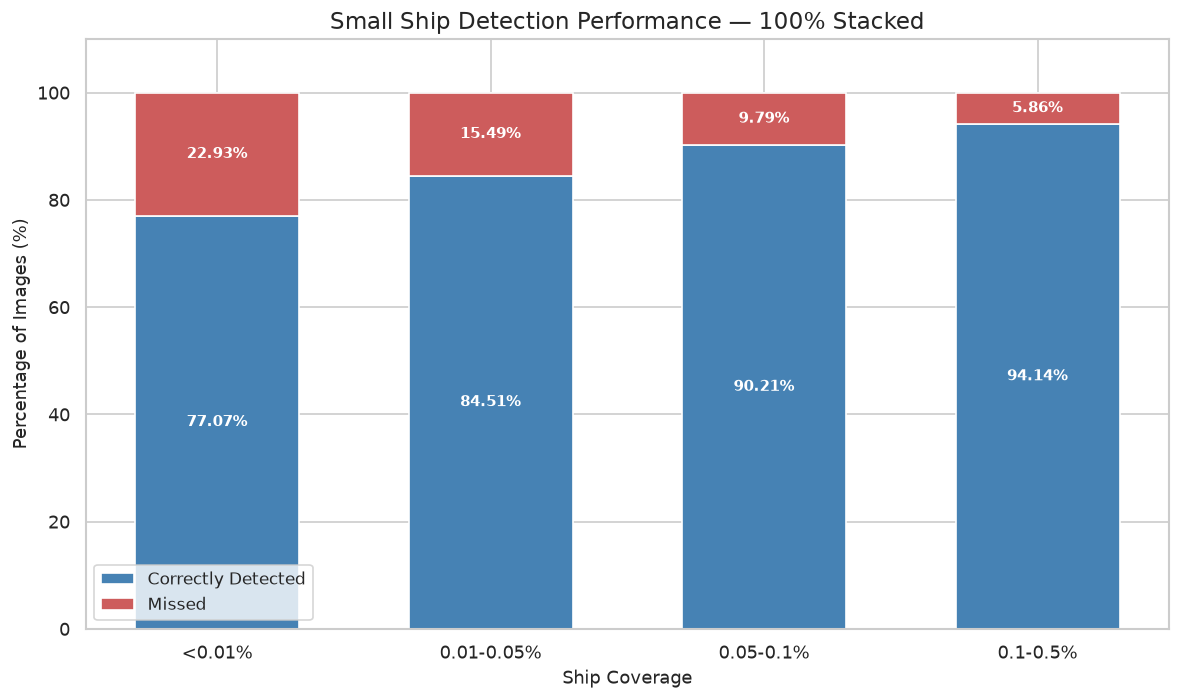

COMPLETE SHIP COVERAGE ANALYSIS


,coverage_group,total,detected,missed,recall
0,<0.01%,375,289,86,77.07
1,0.01-0.05%,1536,1298,238,84.51
2,0.05-0.1%,613,553,60,90.21
3,0.1-0.5%,1894,1783,111,94.14
4,0.5-1%,884,864,20,97.74
5,1-2%,748,721,27,96.39
6,2-5%,327,320,7,97.86
7,>5%,7,7,0,100.00


In [41]:
# Filter only for plotting (< 0.5%)
small_ship_coverage = coverage_analysis[
    coverage_analysis["coverage_group"]
    .astype(str)
    .isin(["<0.01%", "0.01-0.05%", "0.05-0.1%", "0.1-0.5%"])
].copy()

# Calculate percentages within each coverage group
small_ship_coverage["detected_pct"] = (
    small_ship_coverage["detected"] / small_ship_coverage["total"] * 100
)

small_ship_coverage["missed_pct"] = (
    small_ship_coverage["missed"] / small_ship_coverage["total"] * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(small_ship_coverage))

detected_pct = small_ship_coverage["detected_pct"]
missed_pct = small_ship_coverage["missed_pct"]

# Bottom: correctly detected
detected_bars = ax.bar(
    x, detected_pct, label="Correctly Detected", color="steelblue", width=0.6
)

# Top: missed ships
missed_bars = ax.bar(
    x,
    missed_pct,
    bottom=detected_pct,
    label="Missed",
    color="indianred",
    width=0.6,
)

# Percentage labels inside each section
ax.bar_label(
    detected_bars,
    labels=[f"{v:.2f}%" for v in detected_pct],
    label_type="center",
    color="white",
    fontsize=9,
    fontweight="bold",
)

ax.bar_label(
    missed_bars,
    labels=[f"{v:.2f}%" for v in missed_pct],
    label_type="center",
    color="white",
    fontsize=9,
    fontweight="bold",
)

ax.set_title("Small Ship Detection Performance — 100% Stacked")
ax.set_xlabel("Ship Coverage")
ax.set_ylabel("Percentage of Images (%)")
ax.set_xticks(x)
ax.set_xticklabels(small_ship_coverage["coverage_group"])
ax.set_ylim(0, 110)
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

# Complete numerical details for all eight groups
print("COMPLETE SHIP COVERAGE ANALYSIS")

display(
    coverage_analysis[
        ["coverage_group", "total", "detected", "missed", "recall"]
    ].round(2)
)

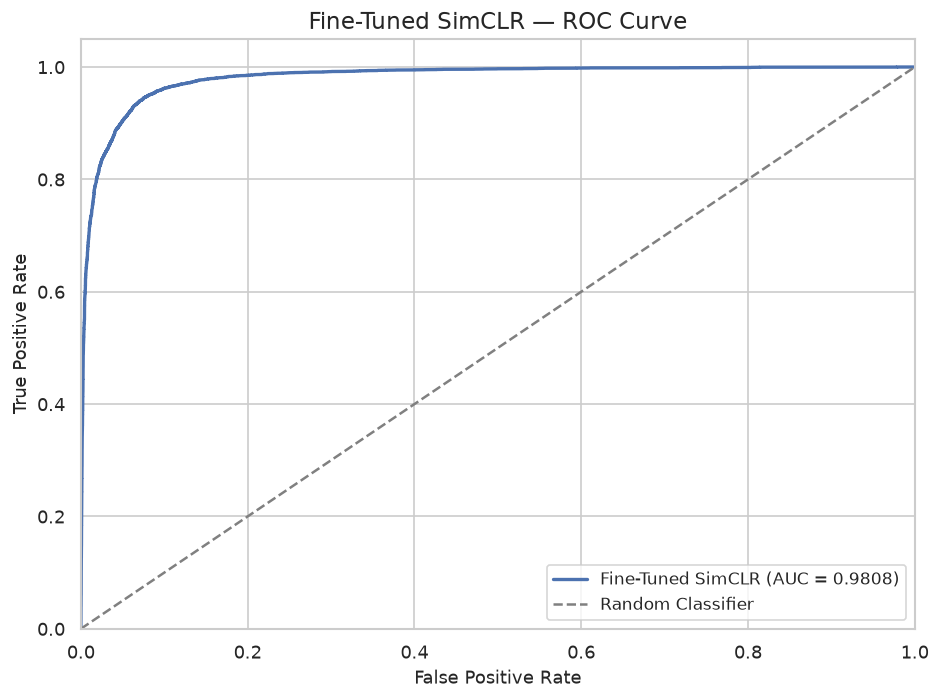

Test ROC-AUC: 0.9808


In [44]:
from sklearn.metrics import roc_auc_score, roc_curve

fpr, tpr, thresholds = roc_curve(all_labels, all_probabilities)

roc_auc = roc_auc_score(all_labels, all_probabilities)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr, tpr, linewidth=2, label=f"Fine-Tuned SimCLR (AUC = {roc_auc:.4f})"
)

ax.plot(
    [0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier"
)

ax.set_title("Fine-Tuned SimCLR — ROC Curve")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"Test ROC-AUC: {roc_auc:.4f}")

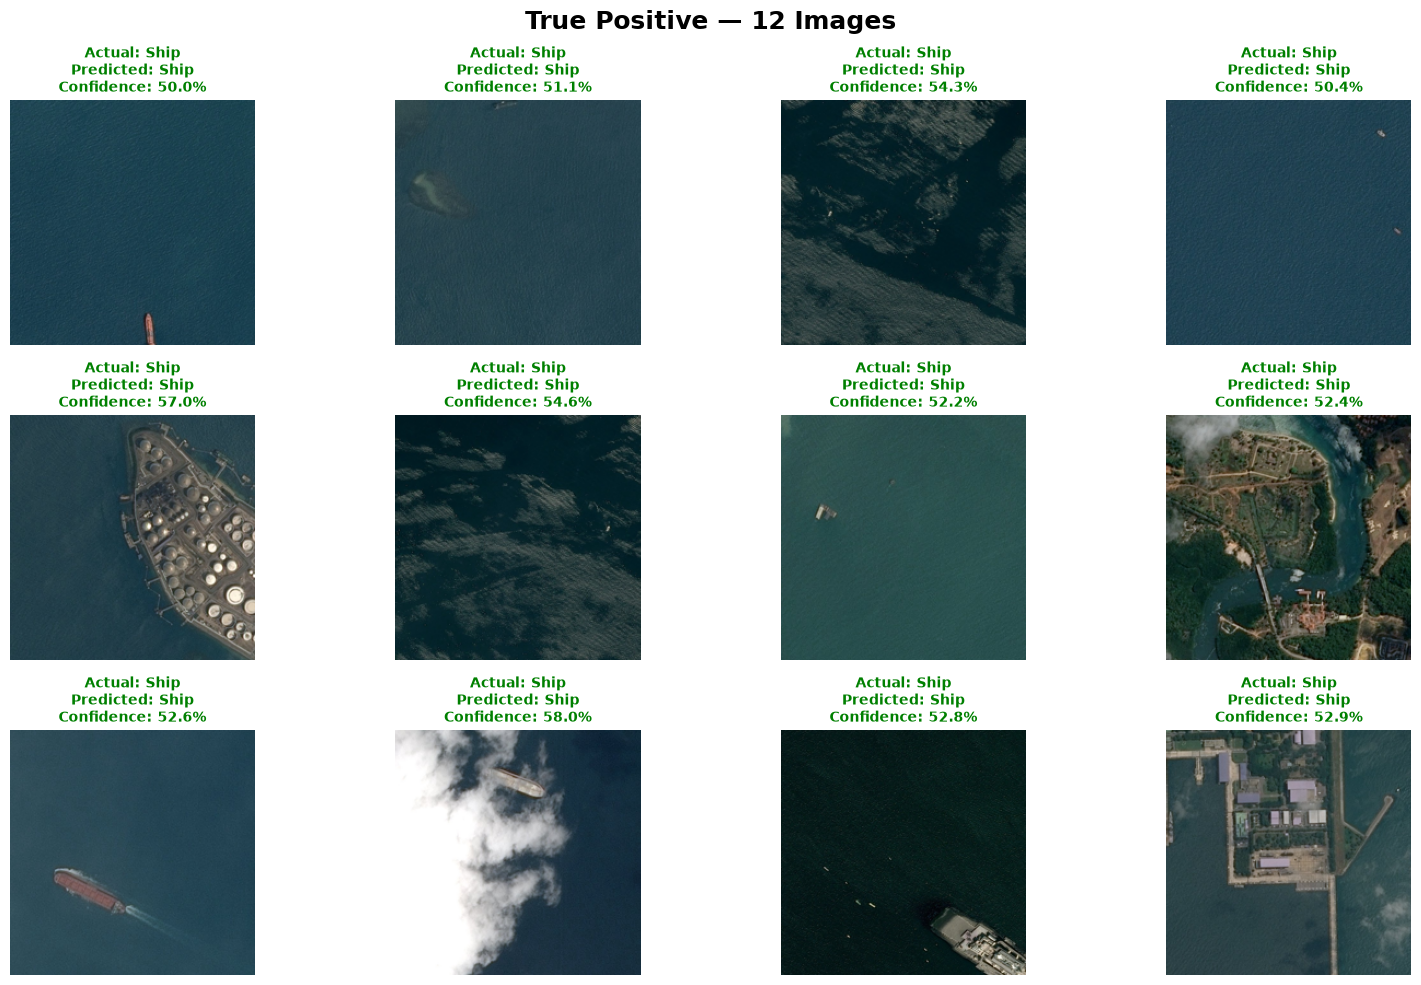

True Positive: 12 images displayed


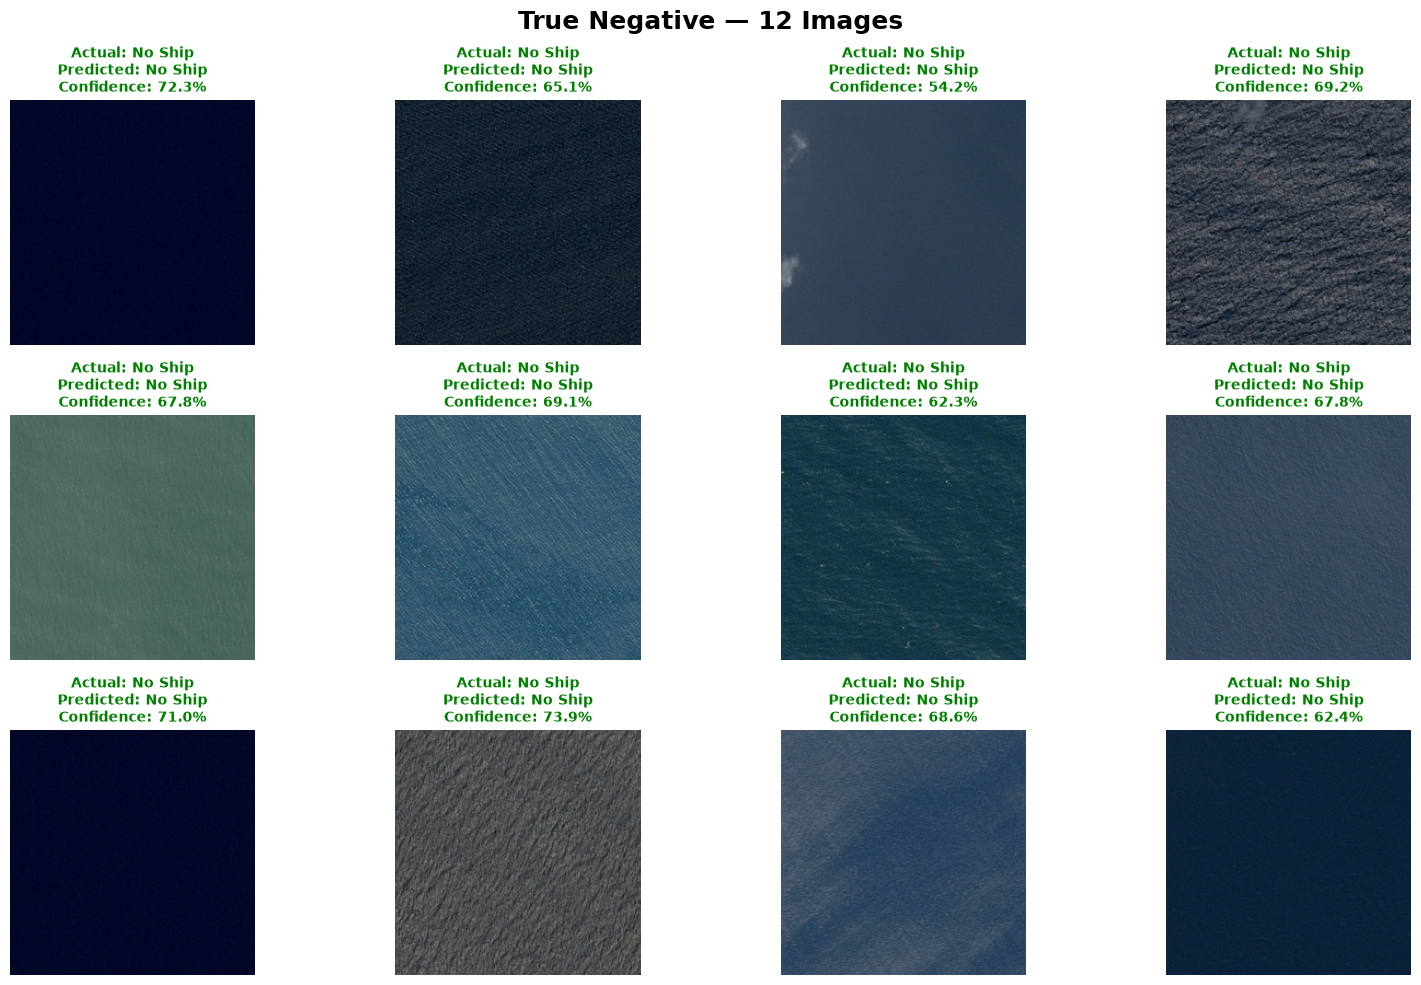

True Negative: 12 images displayed


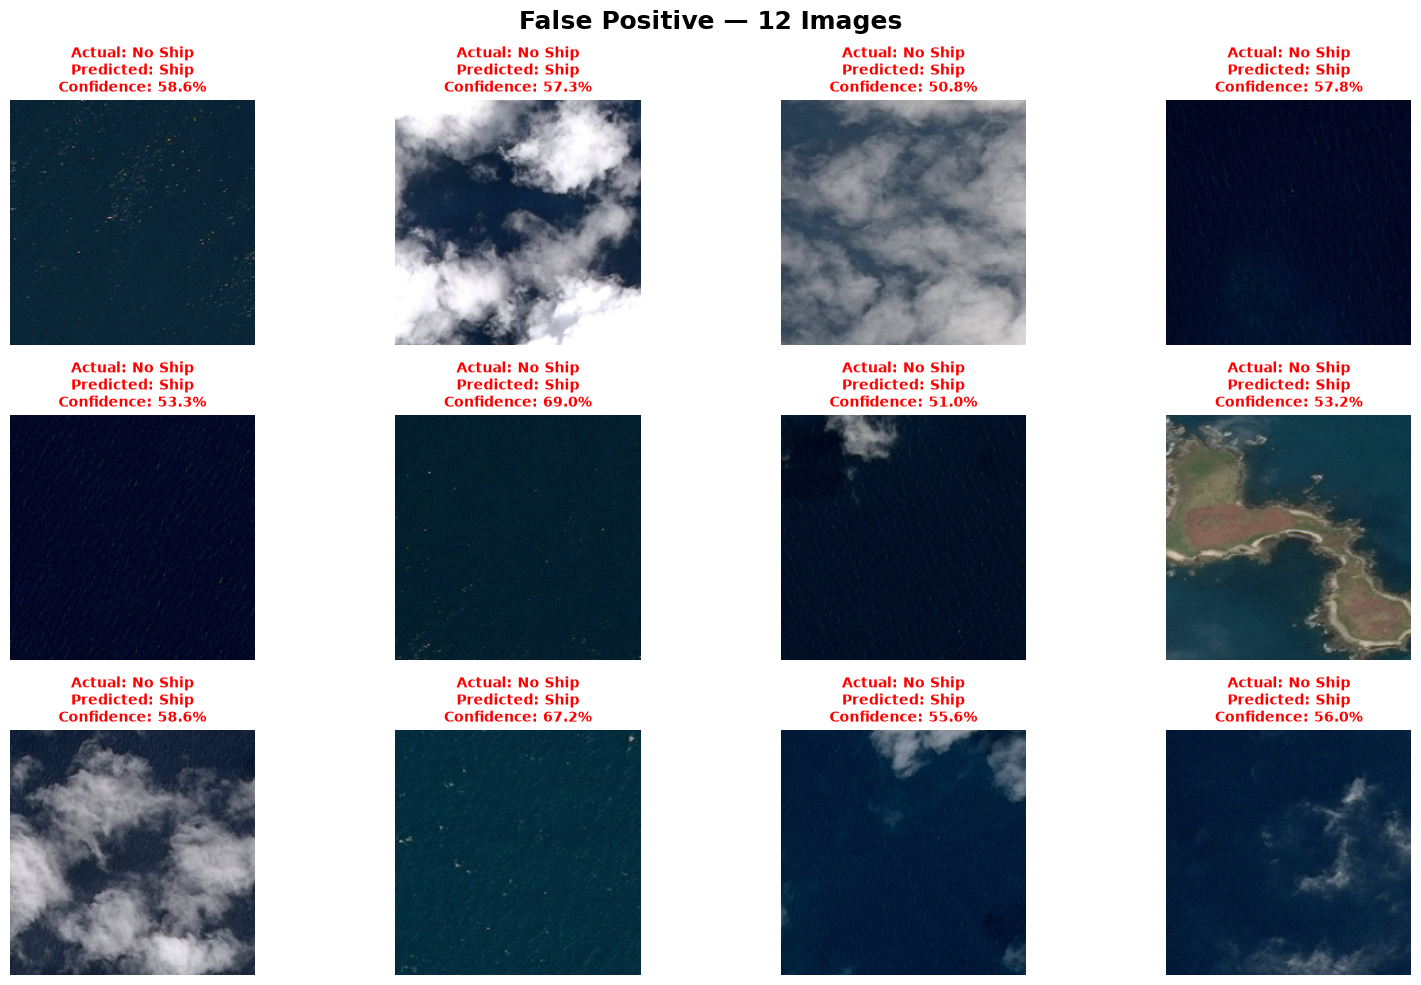

False Positive: 12 images displayed


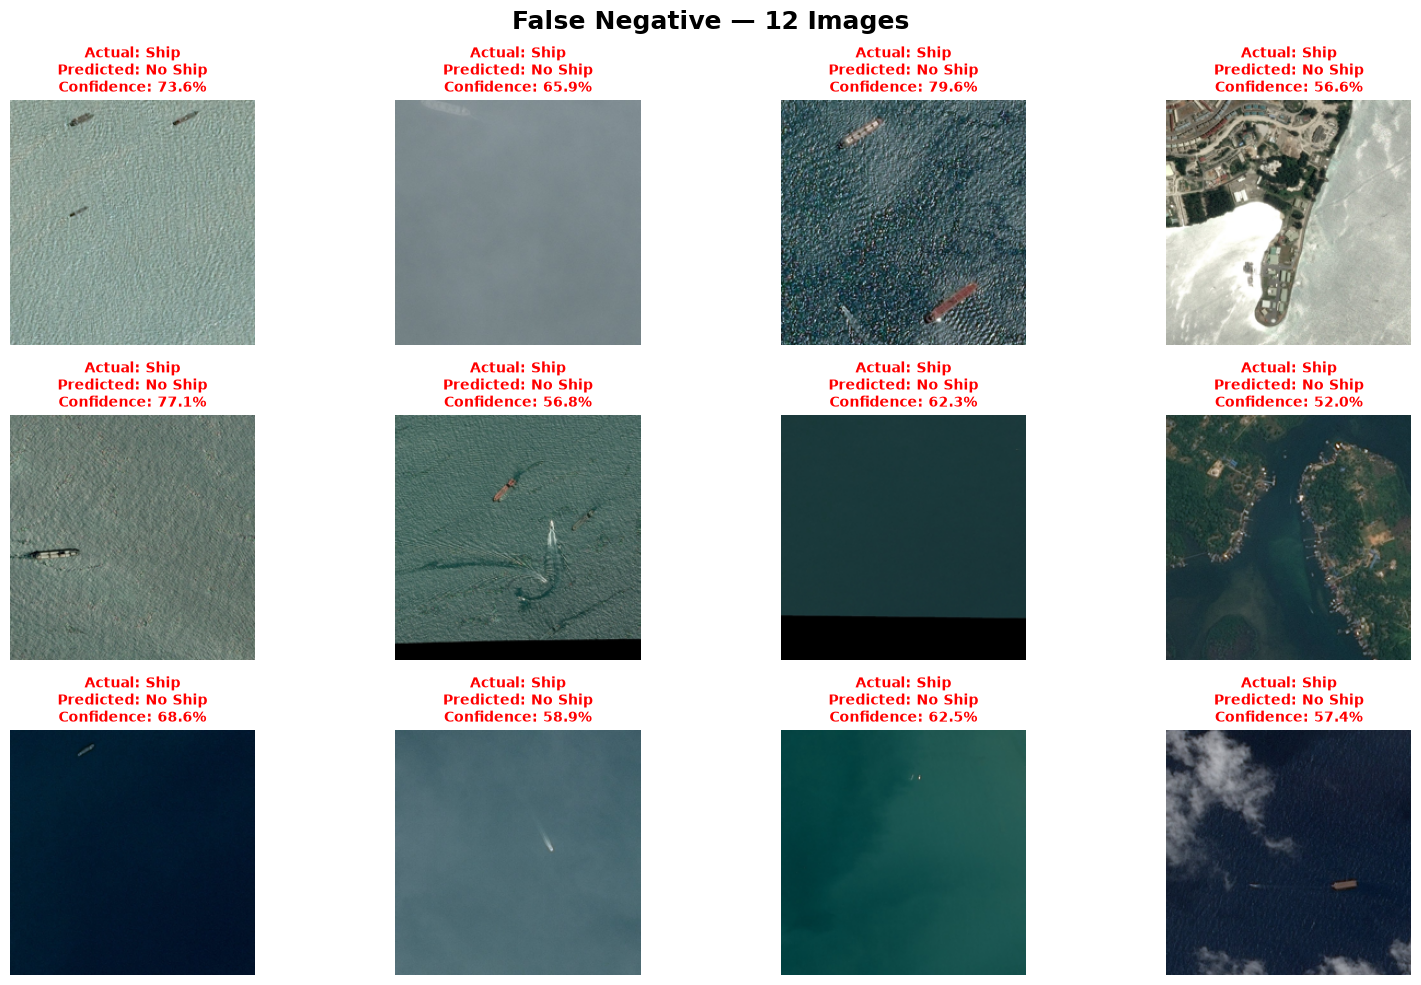

False Negative: 12 images displayed


In [17]:
import matplotlib.pyplot as plt
import torch

model.eval()

results = {
    "True Positive": [],
    "True Negative": [],
    "False Positive": [],
    "False Negative": [],
}

class_names = ["No Ship", "Ship"]

# Collect up to 12 examples of each category
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            actual = labels[i].item()
            predicted = predictions[i].item()

            if actual == 1 and predicted == 1:
                category = "True Positive"
            elif actual == 0 and predicted == 0:
                category = "True Negative"
            elif actual == 0 and predicted == 1:
                category = "False Positive"
            else:
                category = "False Negative"

            if len(results[category]) < 12:
                results[category].append(
                    (
                        images[i].cpu().clone(),
                        actual,
                        predicted,
                        probabilities[i, predicted].item(),
                    )
                )

        # Stop once all categories have 12 examples
        if all(len(samples) == 12 for samples in results.values()):
            break


# ImageNet normalization values
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


# Create four separate figures
for category, samples in results.items():
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))

    fig.suptitle(
        f"{category} — {len(samples)} Images", fontsize=18, fontweight="bold"
    )

    for i, ax in enumerate(axes.flat):
        if i < len(samples):
            image, actual, predicted, confidence = samples[i]

            # Undo normalization
            image = image * std + mean
            image = image.permute(1, 2, 0).clamp(0, 1)

            ax.imshow(image)

            color = "green" if actual == predicted else "red"

            ax.set_title(
                f"Actual: {class_names[actual]}\n"
                f"Predicted: {class_names[predicted]}\n"
                f"Confidence: {confidence:.1%}",
                color=color,
                fontsize=10,
                fontweight="bold",
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"{category}: {len(samples)} images displayed")
